In [90]:
from fastai.basics import DataBlock, RandomSplitter
from fastai.vision.all import ImageBlock, CategoryBlock, get_image_files, Resize, parent_label, vision_learner, resnet18, error_rate, ClassificationInterpretation, RandomResizedCrop, PadMode, ResizeMethod, aug_transforms

In [91]:
images = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter = RandomSplitter(valid_pct=.2, seed=42),
    item_tfms=Resize(256),
    
    batch_tfms=aug_transforms(
        mult=2
    ),
    get_y=parent_label
)

In [92]:
path = "data/"
dls = images.dataloaders(path, bs=32)


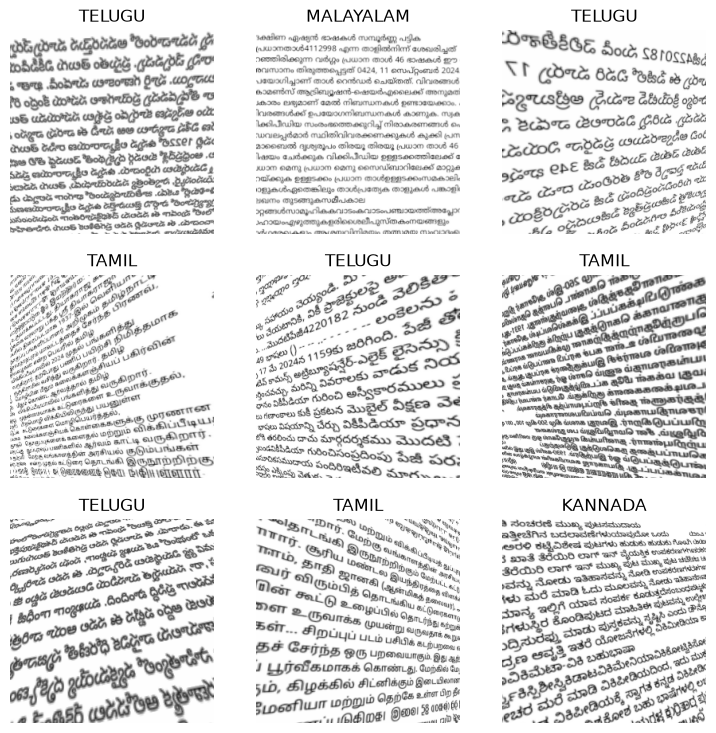

In [93]:
dls.show_batch()

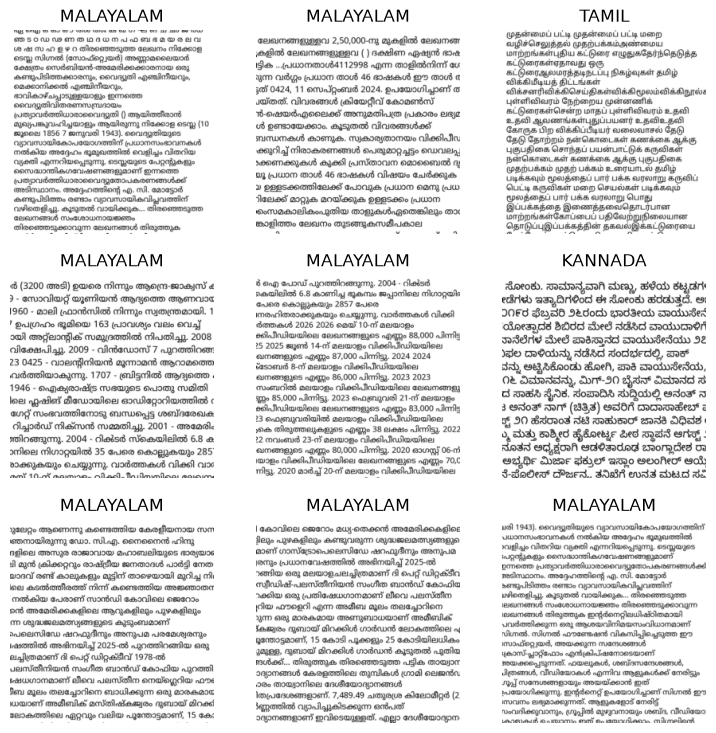

In [94]:
dls.valid.show_batch()

In [95]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(10)

epoch,train_loss,valid_loss,error_rate,time
0,0.553418,0.119269,0.037500,01:19


epoch,train_loss,valid_loss,error_rate,time
0,0.170610,0.041477,0.013750,01:24
1,0.104642,0.001519,0.001250,01:18
2,0.099247,0.044421,0.013750,01:16
3,0.065653,0.006158,0.002500,01:50
4,0.051996,0.002933,0.000000,01:49
5,0.022317,0.000045,0.000000,01:30
6,0.030636,0.000099,0.000000,01:31
7,0.023070,0.000323,0.000000,01:24
8,0.011491,0.000236,0.000000,01:16
9,0.012222,0.000204,0.000000,01:31


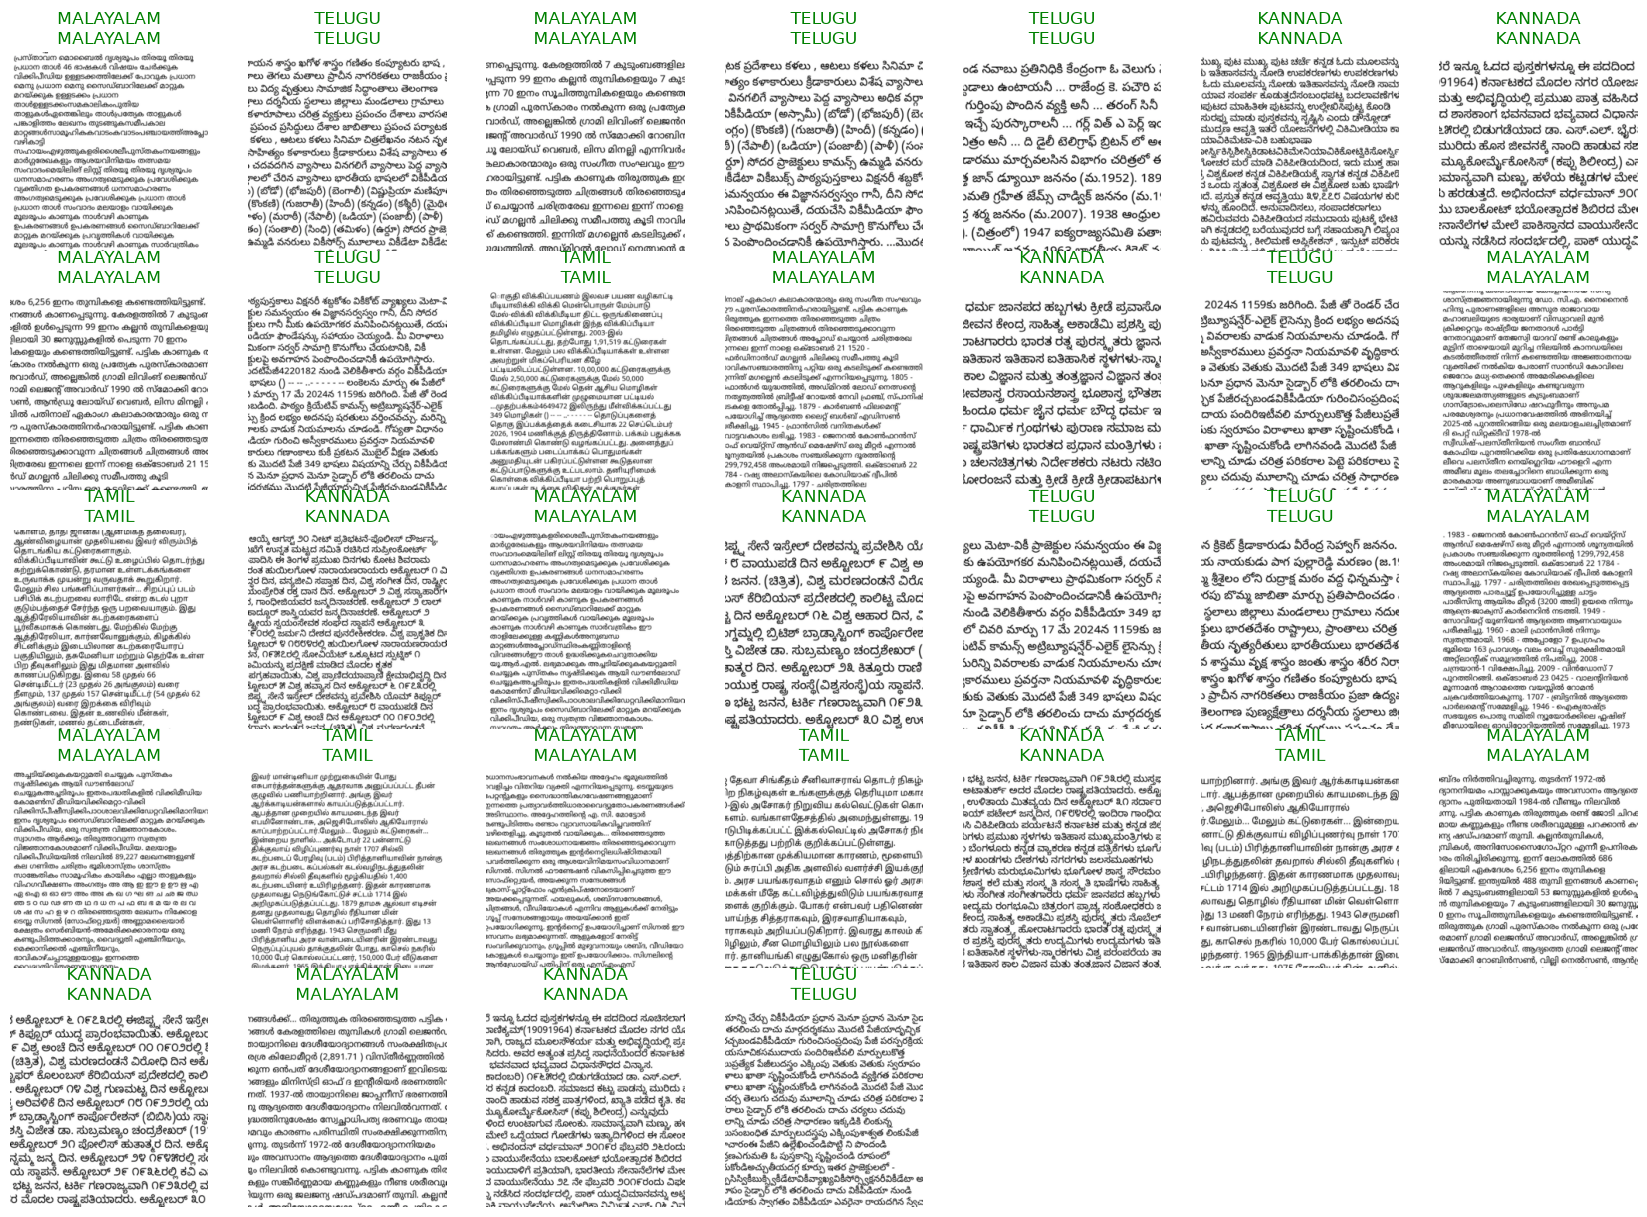

In [96]:
learn.show_results(max_n=100)

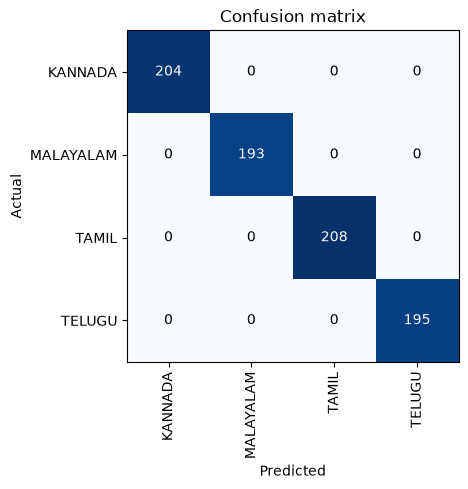

In [97]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

In [104]:
print("Classes:", dls.vocab)
print("Training images:", len(dls.train_ds))
print("Validation images:", len(dls.valid_ds))

Classes: ['KANNADA', 'MALAYALAM', 'TAMIL', 'TELUGU']
Training images: 3200
Validation images: 800


In [105]:
from PIL import Image, ImageDraw, ImageFont
fonts = {
    "TAMIL": "fonts/Noto_Sans_Tamil/static/NotoSansTamil-Regular.ttf",
    "MALAYALAM": "fonts/Noto_Sans_Malayalam/static/NotoSansMalayalam-Regular.ttf",
    "TELUGU": "fonts/Noto_Sans_Telugu/static/NotoSansTelugu-Regular.ttf",
    "KANNADA": "fonts/Noto_Sans_Kannada/static/NotoSansKannada-Regular.ttf",
}
    
def text_to_image(text, language):
    font = ImageFont.truetype(
        fonts[language],
        random.randint(20, 40)
    )
    padding = 20
    max_width = 1000 
    
    temp = Image.new("RGB", (1, 1))
    draw = ImageDraw.Draw(temp)
    
    lines = []
    line = ""
    
    for word in text.split():
        test = f"{line} {word}".strip()
    
        if draw.textlength(test, font=font) <= max_width:
            line = test
        else:
            if line:
                lines.append(line)
            line = word
    
    if line:
        lines.append(line)
    
    wrapped_text = "\n".join(lines)
    
    bbox = draw.multiline_textbbox(
        (0, 0), wrapped_text, font=font, spacing=8
    )
    # print(bbox)
    width = max_width + padding * 2
    height = bbox[3] - bbox[1] + padding * 2
    
    # Create image and draw text
    img = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(img)
    
    draw.multiline_text(
        (padding, padding - bbox[1]),
        wrapped_text,
        font=font,
        fill="black",
        spacing=15
    )
    return img

In [106]:

urls = {"TAMIL": "https://ta.wikipedia.org/",
        "MALAYALAM": "https://ml.wikipedia.org/",
        "KANNADA": "https://kn.wikipedia.org/",
        "TELUGU": "https://te.wikipedia.org/",
       }
import random
from bs4 import BeautifulSoup
import requests
custom_headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)',
}

import unicodedata
import string
def clean_text(text, language):
    exceptions = list(map(unicodedata.name, [".", ",", "(", ")", "+", "-"]))
    remove = "•\xa0"
    result = ""
    for c in text:
        if c in set(string.whitespace + remove):
            if len(result) != 0 and result[len(result)-1] != " ":
                result+=" "
            continue
    
        if unicodedata.name(c) in exceptions or unicodedata.name(c).split()[0] == "DIGIT" or unicodedata.name(c).split()[0] == language:   
            result+=c
    return result

texts = []
for i in range(10):
    language = random.choice(list(urls.keys()))
    # print(language)
    random_url = urls[language] + "wiki/Special:Random"
    # print(random_url)
    response = requests.get(random_url, headers=custom_headers)
    if response.status_code != 200: 
            print("non 200 status returned")
            print("waiting 5 seconds")
            time.sleep(5)
            continue
    beautifulsoup = BeautifulSoup(response.text)
    text = clean_text(beautifulsoup.text, language)
    texts.append((text[:1000], language))

# print(texts)
for text, language in texts:
    img = text_to_image(text, language)
    print(img.size)
    print(f"actual {language}, predicted:{learn.predict(img)}")

(1040, 1043)


actual TAMIL, predicted:('TAMIL', tensor(2), tensor([7.2532e-07, 4.4868e-08, 1.0000e+00, 5.4406e-08]))
(1040, 312)


actual TELUGU, predicted:('TELUGU', tensor(3), tensor([1.6808e-06, 3.2778e-08, 1.1884e-07, 1.0000e+00]))
(1040, 415)


actual TELUGU, predicted:('TELUGU', tensor(3), tensor([1.2722e-07, 1.2743e-08, 3.0570e-08, 1.0000e+00]))
(1040, 598)


actual MALAYALAM, predicted:('MALAYALAM', tensor(1), tensor([2.4193e-09, 1.0000e+00, 3.9632e-07, 3.6055e-07]))
(1040, 612)


...

actual TELUGU, predicted:('TELUGU', tensor(3), tensor([1.5910e-06, 9.6236e-07, 5.7878e-08, 1.0000e+00]))
(1040, 585)


actual TELUGU, predicted:('TELUGU', tensor(3), tensor([9.5063e-06, 9.1689e-07, 1.5303e-07, 9.9999e-01]))
(1040, 534)


actual TELUGU, predicted:('TELUGU', tensor(3), tensor([1.6085e-07, 1.4756e-07, 1.5461e-08, 1.0000e+00]))
(1040, 1205)


actual TAMIL, predicted:('TAMIL', tensor(2), tensor([1.7582e-08, 2.9797e-09, 1.0000e+00, 6.7452e-10]))
(1040, 720)


actual MALAYALAM, predicted:('MALAYALAM', tensor(1), tensor([5.0169e-11, 1.0000e+00, 4.9896e-10, 7.3009e-11]))


In [107]:
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(learn, f)